In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("selected_features_for_clustering.csv")

print("Shape:", df.shape)
df.head()

Shape: (20000, 10)


,Routine_Task_Percentage,Creativity_Requirement,Tasks_Automated_Percentage,Job_Level_Encoded,Human_Interaction_Level,AI_Training_Hours,AI_Usage_Hours_Per_Week,Years_of_Experience,AI_Adoption_Level_Encoded,Number_of_AI_Tools_Used
0,84,21,40,0,94,26,7,6,1,5
1,30,84,14,0,68,9,2,14,0,2
2,12,86,6,2,71,3,1,7,0,0
3,90,18,67,0,21,26,10,6,1,3
4,49,52,26,0,72,19,13,12,1,5


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Scaled shape:", X_scaled.shape)

Scaled shape: (20000, 10)


In [5]:
final_k = 3

kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(df["Cluster"].value_counts())

print("\nSilhouette Score:", silhouette_score(X_scaled, df["Cluster"]))

Cluster counts:
Cluster
2    10431
1     8162
0     1407
Name: count, dtype: int64

Silhouette Score: 0.3357829761779386


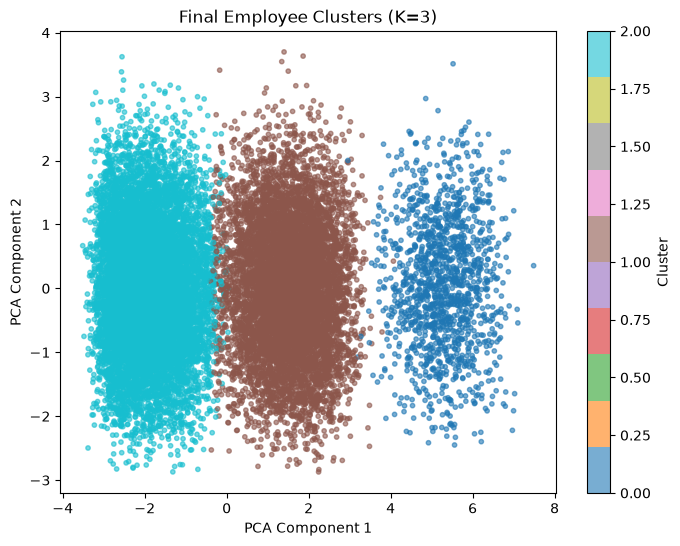

In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df["Cluster"],
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Final Employee Clusters (K=3)")
plt.colorbar(label="Cluster")
plt.show()

In [7]:
cluster_profile = df.groupby("Cluster").mean()
cluster_profile

,Routine_Task_Percentage,Creativity_Requirement,Tasks_Automated_Percentage,Job_Level_Encoded,Human_Interaction_Level,AI_Training_Hours,AI_Usage_Hours_Per_Week,Years_of_Experience,AI_Adoption_Level_Encoded,Number_of_AI_Tools_Used
Cluster,,,,,,,,,,
0,85.969439,13.781095,62.132196,0.669510,59.054016,49.532338,22.730633,7.358920,2.000000,7.472637
1,70.386057,29.253982,50.840480,0.706567,59.932737,16.544474,9.417422,7.225067,0.975251,3.450135
2,32.811811,66.874988,23.219154,0.701659,60.285687,4.572908,2.553159,7.284536,0.009779,1.009779


In [9]:
data = pd.read_csv("final_clustering_data.csv")

X = data.drop(columns=["Layoff_Risk"])
y = data["Layoff_Risk"]

X_scaled = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data["Cluster"] = kmeans.fit_predict(X_scaled)

risk_table = pd.crosstab(
    data["Cluster"],
    data["Layoff_Risk"],
    normalize="index"
)

risk_table

Layoff_Risk,High,Low,Medium
Cluster,,,
0,0.808102,0.011372,0.180526
1,0.592134,0.073144,0.334722
2,0.079283,0.574154,0.346563


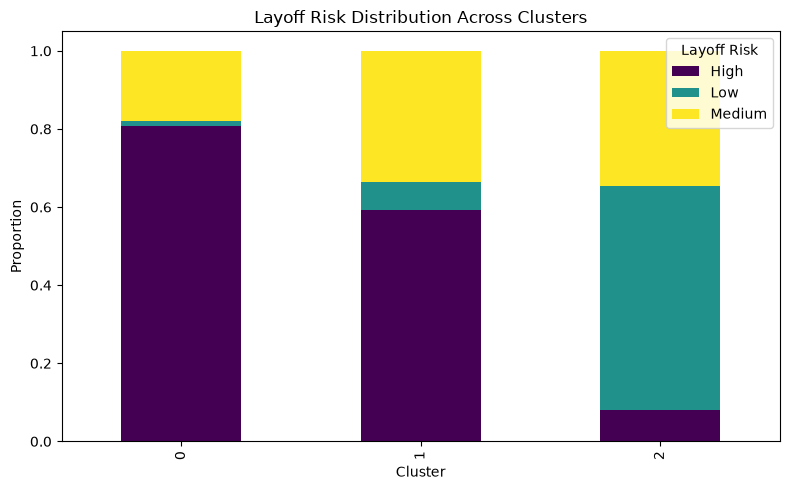

In [10]:
risk_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    colormap="viridis"
)

plt.title("Layoff Risk Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Proportion")
plt.legend(title="Layoff Risk")
plt.tight_layout()
plt.show()

In [11]:
import joblib

# Save scaler and trained KMeans model
joblib.dump(scaler, "scaler.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")

print("Scaler and KMeans model saved successfully")

Scaler and KMeans model saved successfully


In [1]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("\nRequirements:\n")

packages = [
    "streamlit",
    "pandas",
    "numpy",
    "scikit-learn",
    "joblib",
    "matplotlib",
    "seaborn"
]

for package in packages:
    try:
        print(f"{package}=={version(package)}")
    except PackageNotFoundError:
        print(f"# {package}: NOT INSTALLED in this notebook environment")

Python executable: E:\job\New folder\python.exe
Python version: 3.14.6

Requirements:

streamlit==1.58.0
pandas==3.0.3
numpy==2.4.6
scikit-learn==1.9.0
joblib==1.5.3
matplotlib==3.11.0
seaborn==0.13.2
